In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics

In [2]:
df = pd.read_csv('C:/Users/guilherme_doge1/Desktop/Ciência de Dados/Aula 13 - 09-11-2026/producao_automatizada_weg_1000.csv', sep=',')

In [4]:
display(df.head())

,Sensores_Automacao,Robotica_Atuadores,Manutencao_Preventiva,Volume_Produzido
0,118.6,11.7,24.6,15.2
1,285.7,28.5,23.5,25.1
2,222.3,44.0,73.0,27.8
3,183.6,37.4,23.7,19.5
4,55.2,40.9,25.4,15.7


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Sensores_Automacao     1000 non-null   float64
 1   Robotica_Atuadores     1000 non-null   float64
 2   Manutencao_Preventiva  1000 non-null   float64
 3   Volume_Produzido       1000 non-null   float64
dtypes: float64(4)
memory usage: 31.4 KB


In [6]:
display(df.corr())

,Sensores_Automacao,Robotica_Atuadores,Manutencao_Preventiva,Volume_Produzido
Sensores_Automacao,1.000000,0.029337,0.014529,0.858330
Robotica_Atuadores,0.029337,1.000000,0.027081,0.360105
Manutencao_Preventiva,0.014529,0.027081,1.000000,0.375065
Volume_Produzido,0.858330,0.360105,0.375065,1.000000


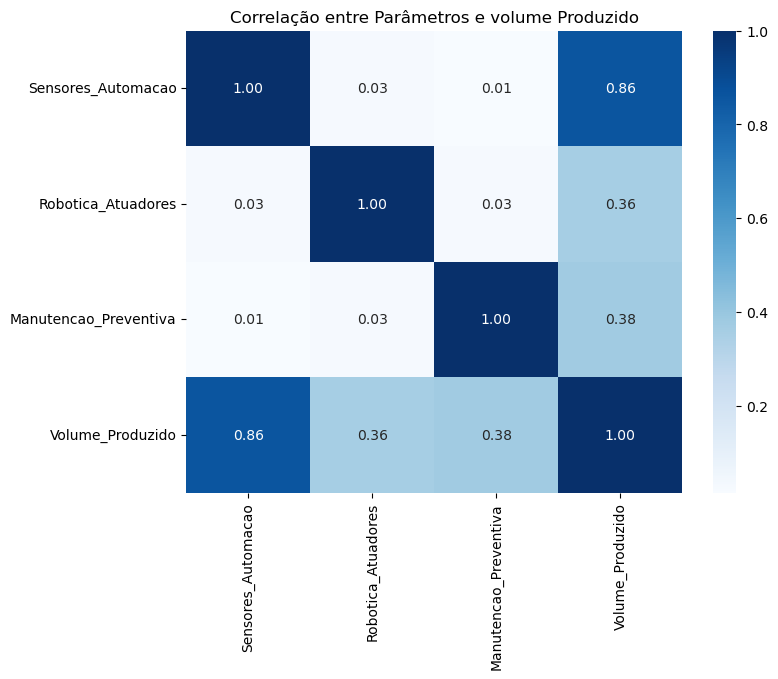

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlação entre Parâmetros e volume Produzido')
plt.show()

In [14]:
x = df[['Sensores_Automacao', 'Robotica_Atuadores', 'Manutencao_Preventiva']]
y = df['Volume_Produzido']

x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.2, random_state=42)

In [21]:
modelo_regressao_linear = LinearRegression()
modelo_arvore_regressora = RandomForestRegressor(random_state=42)

In [23]:
modelo_regressao_linear.fit(x_treino, y_treino)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [24]:
modelo_arvore_regressora.fit(x_treino, y_treino)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [25]:
previsao_regressao_linear = modelo_regressao_linear.predict(x_teste)
previsao_arvore_regressora = modelo_arvore_regressora.predict(x_teste)

In [31]:
print(f'Regressão Linear: {metrics.r2_score(y_teste, previsao_regressao_linear):.2%}')

Regressão Linear: 97.29%


In [32]:
print(f'Random Forest: {metrics.r2_score(y_teste, previsao_arvore_regressora):.2%}')

Random Forest: 95.45%


In [39]:
novos_investimentos = pd.DataFrame({
    'Sensores_Automacao': [150.0, 250.0, 50.0],
    'Robotica_Atuadores': [30.0, 45.0, 10.0],
    'Manutencao_Preventiva': [40.0, 60.0, 15.0]
})

previsoes_novos_cenarios = modelo_regressao_linear.predict(novos_investimentos)
novos_investimentos['Volume_Produzido_Previsto (Milhões)'] = previsoes_novos_cenarios

display(novos_investimentos)

,Sensores_Automacao,Robotica_Atuadores,Manutencao_Preventiva,Volume_Produzido_Previsto (Milhões)
0,150.0,30.0,40.0,19.298023
1,250.0,45.0,60.0,27.602910
2,50.0,10.0,15.0,10.014699
